In [1]:
"""
Task 8 pipeline imports: image loading, model inference, post-processing,
analysis, and visualization.
"""

import os
import glob
import math
import random

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import wandb

from tensorflow.keras.models import load_model
from tensorflow.keras import backend as K

from skimage.morphology import (
    skeletonize,
    dilation,
    binary_closing,
    remove_small_objects,
    remove_small_holes,
    disk,
)
from skimage.measure import label, regionprops

from scipy.ndimage import distance_transform_edt


2026-03-26 15:34:22.524750: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Load Trained Segmentation Model


In [2]:
"""
Loads the U-Net model trained in Task 5 for use in the Task 8 pipeline.
"""
# Load the model trained in task5_training.ipynb
MODEL_PATH = "ahmed_245226_Residualunet_model_192px.h5"
model = load_model(MODEL_PATH, compile=False)
print("Model loaded successfully!")


2026-03-26 15:34:30.324806: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1774539270.326708    9701 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 43780 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:25:00.0, compute capability: 8.6


Model loaded successfully!


## Load Test Images


In [3]:
"""
Loads the list of test images for the Task 8 pipeline by scanning a folder.
Prints all detected PNG filenames and the total number of images found.
"""
# Folder for test images
test_images_folder = "Kaggle"

# Find all PNG images in that folder
test_image_paths = sorted(glob.glob(test_images_folder + "/*.png"))

print("Found test images:\n")
for p in test_image_paths:
    print(" -", os.path.basename(p))

print("\nTotal images found:", len(test_image_paths))


Found test images:

 - test_image_01.png
 - test_image_02.png
 - test_image_03.png
 - test_image_04.png
 - test_image_05.png
 - test_image_06.png
 - test_image_07.png
 - test_image_08.png
 - test_image_09.png
 - test_image_10.png
 - test_image_11.png
 - test_image_12.png
 - test_image_13.png
 - test_image_14.png
 - test_image_15.png
 - test_image_16.png
 - test_image_17.png
 - test_image_18.png
 - test_image_19.png

Total images found: 19


In [4]:
"""
Logs into Weights & Biases (wandb) and starts a run to track Task 8 inference settings
(e.g., patch size, model path, and number of test images).
"""


wandb.login()
wandb.init(
    project="task8_inference",
    entity="245226-breda-university-of-applied-sciences",
    config={
        "patch_size": 192,
        "model_path": MODEL_PATH,
        "num_test_images": len(test_image_paths)
    }
)


wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter:

  ········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.


ValueError: API key must be at least 40 characters long, yours was 16

## Crop Petri Dish Region from Test Images


test_image_01.png:
   Original: (3006, 4202)
   Crop:     (2810, 2799)
test_image_02.png:
   Original: (3006, 4202)
   Crop:     (2810, 2801)
test_image_03.png:
   Original: (3006, 4202)
   Crop:     (2810, 2801)
test_image_04.png:
   Original: (3006, 4202)
   Crop:     (2778, 2736)
test_image_05.png:
   Original: (3006, 4202)
   Crop:     (2778, 2736)
test_image_06.png:
   Original: (3006, 4202)
   Crop:     (2778, 2737)
test_image_07.png:
   Original: (3006, 4202)
   Crop:     (2779, 2736)
test_image_08.png:
   Original: (3006, 4202)
   Crop:     (2810, 2800)
test_image_09.png:
   Original: (3006, 4202)
   Crop:     (2809, 2800)
test_image_10.png:
   Original: (3006, 4202)
   Crop:     (2778, 2736)
test_image_11.png:
   Original: (3006, 4202)
   Crop:     (2810, 2800)
test_image_12.png:
   Original: (2999, 4202)
   Crop:     (2810, 2800)
test_image_13.png:
   Original: (3006, 4202)
   Crop:     (2810, 2800)
test_image_14.png:
   Original: (3006, 4202)
   Crop:     (2778, 2736)
test_i

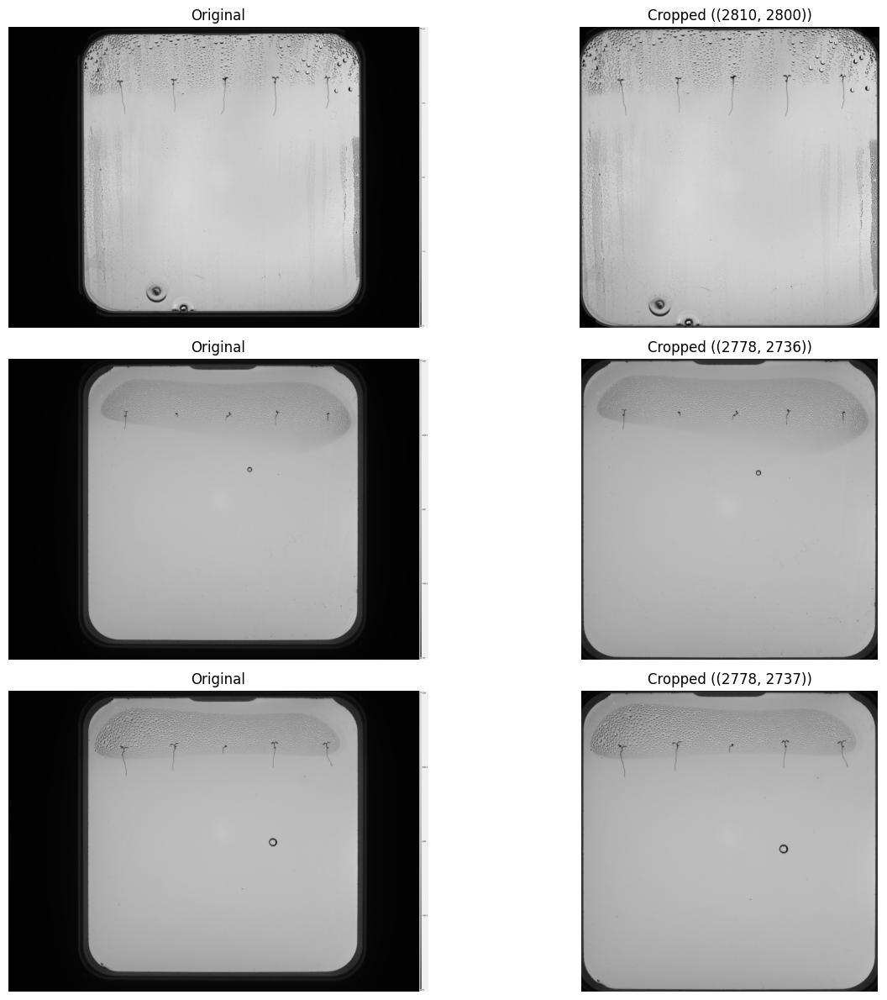

In [6]:
"""
Crops the Petri dish area from each test image using a brightness-based method (blur + Otsu).
Stores the cropped results and the crop coordinates (metadata), and visualizes 3 examples
(original vs cropped) to verify the cropping works on the dataset.
"""

def crop_and_show_3(image_paths):
    """
    Detects and crops the Petri dish region for a list of images.
    Returns:
      - cropped_images: list of cropped grayscale images
      - crop_metadata: list of crop boxes (minr, minc, maxr, maxc) or "fallback"
    """
    cropped_images = []
    crop_metadata = []

    for path in image_paths:
        img = cv2.imread(path, 0)
        h0, w0 = img.shape

        # 1) Blur + Otsu threshold to find bright dish area
        blur = cv2.GaussianBlur(img, (9, 9), 0)
        _, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

        # Keep bright region and remove small noise
        mask = (thresh == 255)
        mask = remove_small_objects(mask, min_size=5000)

        # Find connected components and select the largest one
        labeled = label(mask)
        regions = regionprops(labeled)

        # Fallback if dish is not detected
        if not regions:
            print(f"[WARNING] No bright region found in {os.path.basename(path)}. Using fallback.")
            crop_size = min(h0, w0)
            sy = (h0 - crop_size) // 2
            sx = (w0 - crop_size) // 2
            cropped = img[sy:sy+crop_size, sx:sx+crop_size]
            cropped_images.append(cropped)
            crop_metadata.append("fallback")
            continue

        largest = max(regions, key=lambda r: r.area)
        minr, minc, maxr, maxc = largest.bbox

        # Expand crop slightly to include rim
        expand = 18
        minr = max(minr - expand, 0)
        minc = max(minc - expand, 0)
        maxr = min(maxr + expand, h0)
        maxc = min(maxc + expand, w0)

        cropped = img[minr:maxr, minc:maxc]
        cropped_images.append(cropped)
        crop_metadata.append((minr, minc, maxr, maxc))

        print(f"{os.path.basename(path)}:")
        print(f"   Original: {img.shape}")
        print(f"   Crop:     {cropped.shape}")

    print(f"\nSuccessfully cropped {len(cropped_images)} images.\n")

    # Show 3 random examples (original vs cropped)
    sample_idx = random.sample(range(len(image_paths)), min(3, len(image_paths)))

    plt.figure(figsize=(14, 12))
    for i, idx in enumerate(sample_idx):
        original = cv2.imread(image_paths[idx], 0)
        cropped = cropped_images[idx]

        plt.subplot(3, 2, 2*i + 1)
        plt.imshow(original, cmap='gray')
        plt.title("Original")
        plt.axis("off")

        plt.subplot(3, 2, 2*i + 2)
        plt.imshow(cropped, cmap='gray')
        plt.title(f"Cropped ({cropped.shape})")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    return cropped_images, crop_metadata

cropped_images, crop_info = crop_and_show_3(test_image_paths)


## Apply Padding to Cropped Images


Padded 19 images successfully.
Example original size: (2810, 2799)
Example padded size  : (2880, 2880)


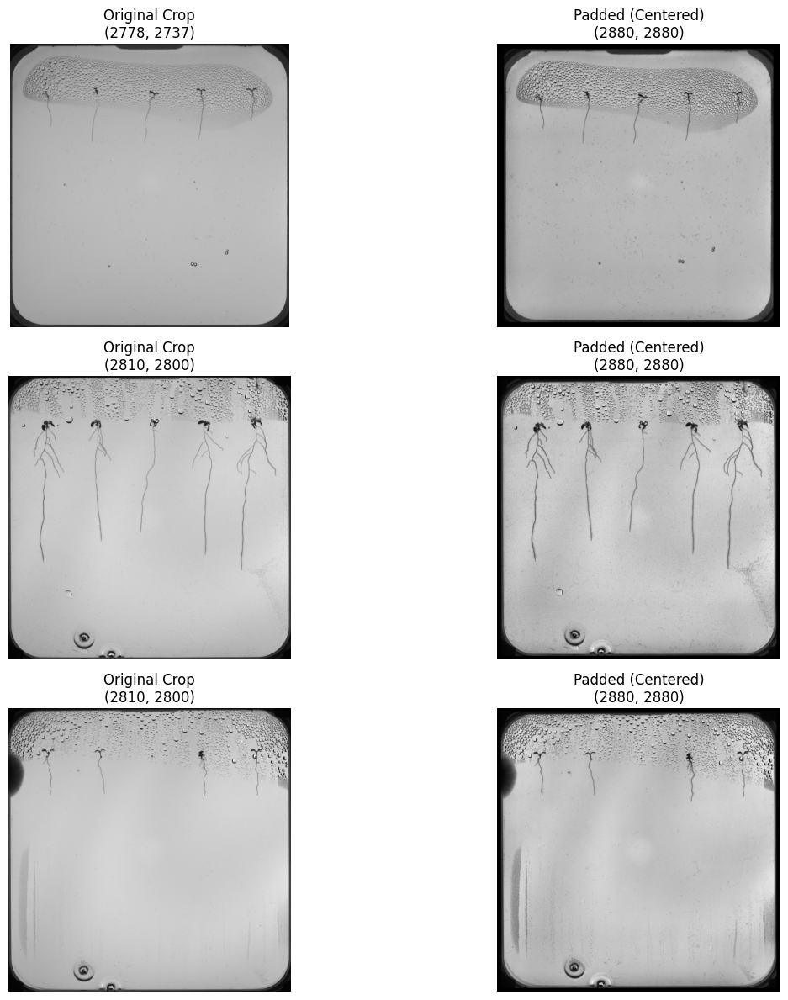

In [7]:
"""
Applies centered padding to each cropped Petri dish image so its size becomes divisible by patch_size.
Also applies CLAHE for contrast improvement, stores padding metadata (offsets and shapes),
and visualizes a few before/after examples to confirm padding is correct.
"""

# Pad image so size is divisible by patch_size (CENTERED)
patch_size = 192

def pad_to_multiple(img, patch_size=192):
    """
    Pads a grayscale image to the nearest multiple of patch_size (centered padding).
    Returns the padded image and a dictionary with padding offsets and shapes.
    """
    h, w = img.shape

    new_h = ((h + patch_size - 1) // patch_size) * patch_size
    new_w = ((w + patch_size - 1) // patch_size) * patch_size

    y_offset = (new_h - h) // 2
    x_offset = (new_w - w) // 2

    # Constant padding to avoid reflected edge artifacts
    padded = cv2.copyMakeBorder(
        img,
        top=y_offset,
        bottom=new_h - h - y_offset,
        left=x_offset,
        right=new_w - w - x_offset,
        borderType=cv2.BORDER_CONSTANT,
        value=0
    )

    return padded, {
        "orig_shape": (h, w),
        "padded_shape": (new_h, new_w),
        "offset": (y_offset, x_offset)
    }

def apply_clahe_u8(img_u8, clip=2.0, grid=(8, 8)):
    """
    Improves contrast using CLAHE (helps roots stand out before prediction).
    """
    clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid)
    return clahe.apply(img_u8)

# Apply padding + CLAHE to all cropped images
padded_images = []
pad_info = []

for crop in cropped_images:
    crop = apply_clahe_u8(crop, clip=2.0, grid=(8, 8))
    padded, info = pad_to_multiple(crop, patch_size=patch_size)

    padded_images.append(padded)
    pad_info.append(info)

print(f"Padded {len(padded_images)} images successfully.")
print("Example original size:", cropped_images[0].shape)
print("Example padded size  :", padded_images[0].shape)

# Show 3 random BEFORE / AFTER padding examples
sample_idx = random.sample(range(len(cropped_images)), min(3, len(cropped_images)))

plt.figure(figsize=(14, 12))
for i, idx in enumerate(sample_idx):
    original = cropped_images[idx]
    padded   = padded_images[idx]

    plt.subplot(3, 2, 2*i + 1)
    plt.imshow(original, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Original Crop\n{original.shape}")
    plt.axis("off")

    plt.subplot(3, 2, 2*i + 2)
    plt.imshow(padded, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Padded (Centered)\n{padded.shape}")
    plt.axis("off")

plt.tight_layout()
plt.show()


## Patch-Based U-Net Inference with Overlap


In [8]:
"""
Runs patch-based U-Net inference with 50% overlap for smoother predictions.

What this cell does:
1) Splits each padded image into overlapping 192x192 patches (step = 96).
2) Predicts a probability mask for each patch.
3) Reconstructs the full mask by averaging overlapping predictions.
4) Thresholds the result (low threshold helps detect thin roots).
5) Stores one predicted binary mask per input image.
"""
# PATCHIFY WITH OVERLAP

def patchify_image(img, patch_size=192, step=96):
    """
    Splits an image into overlapping patches and records each patch position.
    Returns:
      - patches: array of shape (N, patch_size, patch_size)
      - positions: list of (row, col) top-left coordinates for each patch
    """
    patches = []
    positions = []
    h, w = img.shape

    for i in range(0, h - patch_size + 1, step):
        for j in range(0, w - patch_size + 1, step):
            patch = img[i:i+patch_size, j:j+patch_size]
            patches.append(patch)
            positions.append((i, j))

    return np.array(patches), positions

# UNPATCHIFY WITH AVERAGING

def unpatchify_avg(patches, positions, full_h, full_w, patch_size=192):
    """
    Reconstructs the full image by placing predicted patches back and averaging
    in areas where patches overlap.
    """
    reconstructed = np.zeros((full_h, full_w), dtype=np.float32)
    count = np.zeros((full_h, full_w), dtype=np.float32)

    for patch, (i, j) in zip(patches, positions):
        reconstructed[i:i+patch_size, j:j+patch_size] += patch
        count[i:i+patch_size, j:j+patch_size] += 1

    count[count == 0] = 1
    return reconstructed / count

# INFERENCE LOOP

predicted_masks = []

patch_size = 192
step = patch_size // 2  # 50% overlap
threshold = 0.20        # lower threshold helps thin root detection

print(f"Starting UNet prediction for {len(padded_images)} images...\n")

for idx, padded in enumerate(padded_images):
    print(f"Processing image {idx+1}/{len(padded_images)} ...")

    # 1) Patch with overlap
    patches, positions = patchify_image(padded, patch_size, step)
    print(f" Generated {patches.shape[0]} overlapping patches")

    # 2) Prepare input (N,192,192,1) and normalize to [0, 1]
    patches_input = patches[..., np.newaxis].astype(np.float32) / 255.0

    # 3) Predict per patch (returns probabilities)
    preds = model.predict(patches_input, batch_size=1, verbose=0)[..., 0]

    # 4) Reconstruct full probability mask with averaging
    restored = unpatchify_avg(preds, positions, padded.shape[0], padded.shape[1], patch_size)

    # 5) Binarize probability mask
    restored = (restored > threshold).astype(np.uint8)

    predicted_masks.append(restored)

print("\nAll images processed successfully!")


Starting UNet prediction for 19 images...

Processing image 1/19 ...
 Generated 841 overlapping patches


2026-03-26 15:35:54.502270: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f9f1c00caf0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-03-26 15:35:54.502303: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX A6000, Compute Capability 8.6
2026-03-26 15:35:54.532289: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-03-26 15:35:54.634158: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 90701
I0000 00:00:1774539355.970531   10998 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Processing image 2/19 ...
 Generated 841 overlapping patches
Processing image 3/19 ...
 Generated 841 overlapping patches
Processing image 4/19 ...
 Generated 841 overlapping patches
Processing image 5/19 ...
 Generated 841 overlapping patches
Processing image 6/19 ...
 Generated 841 overlapping patches
Processing image 7/19 ...
 Generated 841 overlapping patches
Processing image 8/19 ...
 Generated 841 overlapping patches
Processing image 9/19 ...
 Generated 841 overlapping patches
Processing image 10/19 ...
 Generated 841 overlapping patches
Processing image 11/19 ...
 Generated 841 overlapping patches
Processing image 12/19 ...
 Generated 841 overlapping patches
Processing image 13/19 ...
 Generated 841 overlapping patches
Processing image 14/19 ...
 Generated 841 overlapping patches
Processing image 15/19 ...
 Generated 841 overlapping patches
Processing image 16/19 ...
 Generated 841 overlapping patches
Processing image 17/19 ...
 Generated 841 overlapping patches
Processing image

Image 15:
  RAW original shape  : (3006, 4112)
  Predicted mask shape: (2880, 2880)

Image 4:
  RAW original shape  : (3006, 4202)
  Predicted mask shape: (2880, 2880)

Image 9:
  RAW original shape  : (3006, 4202)
  Predicted mask shape: (2880, 2880)



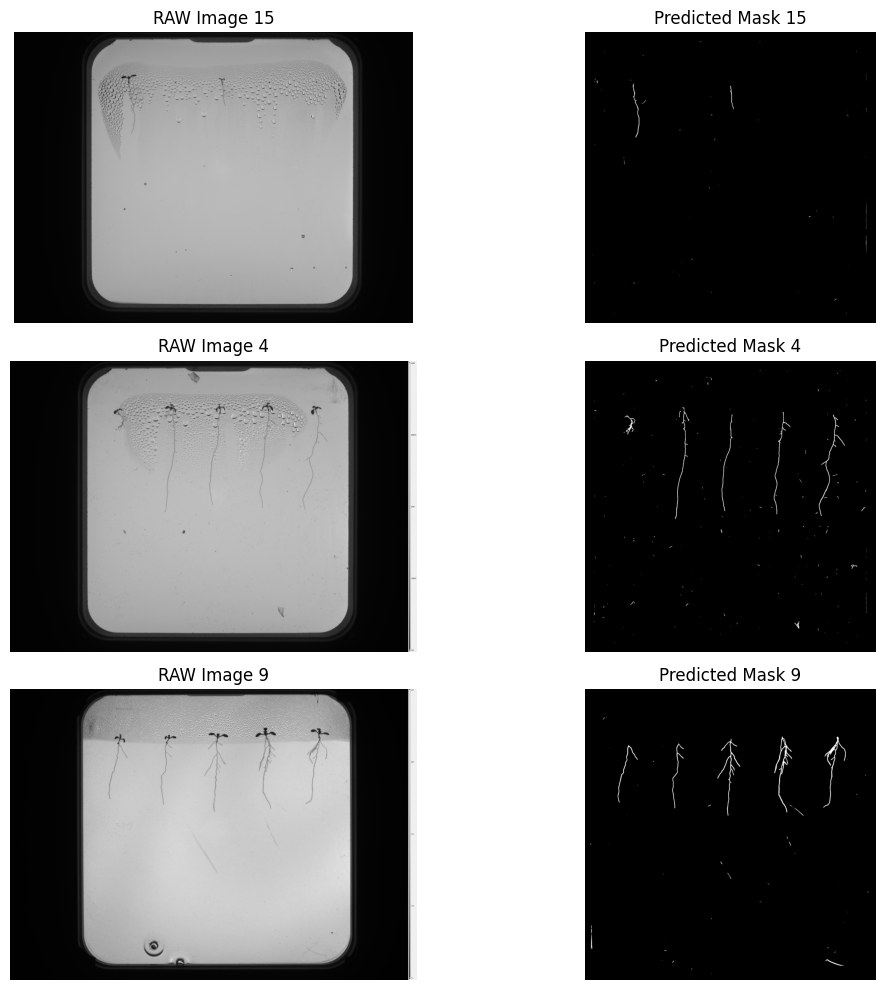

In [9]:
"""
Selects 3 random test images and visualizes the raw input next to the predicted mask.
Also prints the raw image shape and predicted mask shape to check whether sizes match.
"""

# Pick 3 random indices
sample_ids = random.sample(range(len(predicted_masks)), 3)

plt.figure(figsize=(12, 10))

for i, idx in enumerate(sample_ids):

    raw_img = cv2.imread(test_image_paths[idx], 0)   
    pred_mask = predicted_masks[idx]                 

    # Display both
    plt.subplot(3, 2, 2*i + 1)
    plt.imshow(raw_img, cmap='gray')
    plt.title(f"RAW Image {idx+1}")
    plt.axis('off')

    plt.subplot(3, 2, 2*i + 2)
    plt.imshow(pred_mask, cmap='gray')
    plt.title(f"Predicted Mask {idx+1}")
    plt.axis('off')

    # Print shapes for comparison
    print(f"Image {idx+1}:")
    print("  RAW original shape  :", raw_img.shape)
    print("  Predicted mask shape:", pred_mask.shape)
    print()

plt.tight_layout()
plt.show()


## Restore Predicted Masks to Original Image Size


[0] test_image_01.png
  Raw image size   : (3006, 4202)
  Pred mask size   : (2880, 2880)
  Restored size    : (3006, 4202)

[1] test_image_02.png
  Raw image size   : (3006, 4202)
  Pred mask size   : (2880, 2880)
  Restored size    : (3006, 4202)

[2] test_image_03.png
  Raw image size   : (3006, 4202)
  Pred mask size   : (2880, 2880)
  Restored size    : (3006, 4202)

[3] test_image_04.png
  Raw image size   : (3006, 4202)
  Pred mask size   : (2880, 2880)
  Restored size    : (3006, 4202)

[4] test_image_05.png
  Raw image size   : (3006, 4202)
  Pred mask size   : (2880, 2880)
  Restored size    : (3006, 4202)

[5] test_image_06.png
  Raw image size   : (3006, 4202)
  Pred mask size   : (2880, 2880)
  Restored size    : (3006, 4202)

[6] test_image_07.png
  Raw image size   : (3006, 4202)
  Pred mask size   : (2880, 2880)
  Restored size    : (3006, 4202)

[7] test_image_08.png
  Raw image size   : (3006, 4202)
  Pred mask size   : (2880, 2880)
  Restored size    : (3006, 4202)



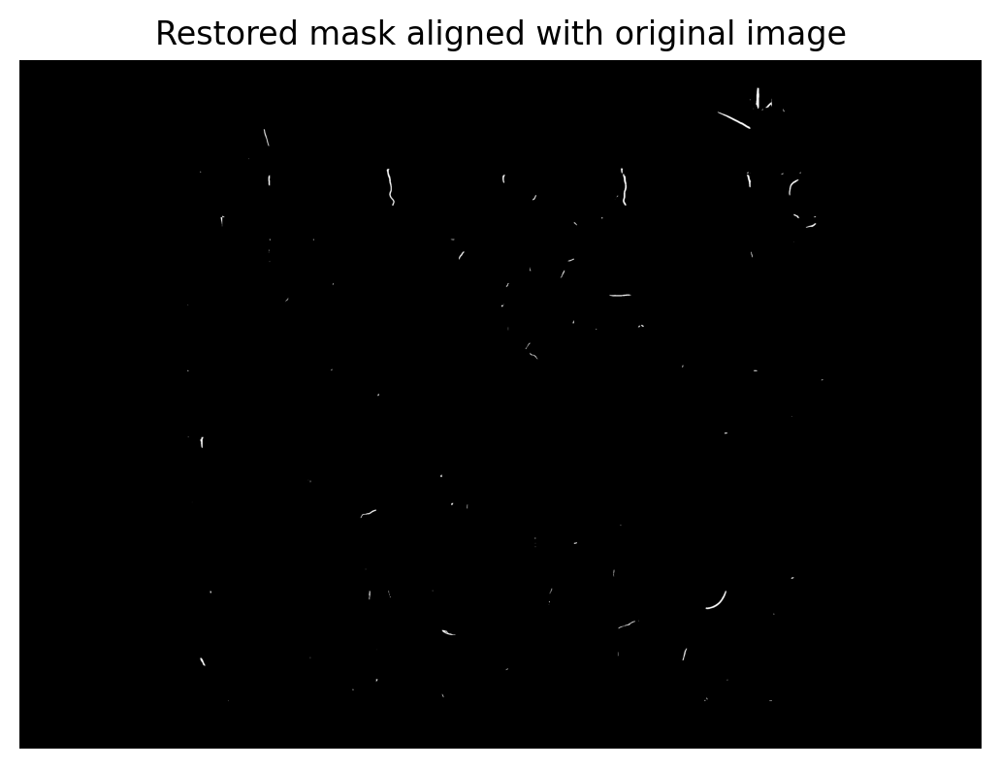

In [10]:
"""
Restores each predicted mask back to the original raw image size.

Steps per image:
1) Use pad_info to remove centered padding (crop out the padded border).
2) Use crop_info to place the mask back into the original raw image coordinates.
3) Print shapes to confirm the restored mask matches the raw image size.
4) Show one example restored mask for a quick visual check.
"""

# RESTORE MASKS TO ORIGINAL IMAGE SIZE
def restore_all(predicted_masks, crop_info, pad_info, image_paths):
    """
    Removes padding and reverses cropping for all predicted masks.
    Returns a list of restored masks that match the original image sizes.
    """
    restored_masks = []

    for idx, (pred_mask, crop_box, pad, path) in enumerate(
        zip(predicted_masks, crop_info, pad_info, image_paths)
    ):
        raw_img = cv2.imread(path, 0)
        orig_h, orig_w = raw_img.shape

        # Crop info (where the Petri dish crop came from)
        minr, minc, maxr, maxc = crop_box
        crop_h = maxr - minr
        crop_w = maxc - minc

        # Padding info (center offsets)
        y_offset, x_offset = pad["offset"]

        # Remove padding (back to cropped image size)
        unpadded = pred_mask[
            y_offset:y_offset + crop_h,
            x_offset:x_offset + crop_w
        ]

        # Restore to original raw image size
        restored = np.zeros((orig_h, orig_w), dtype=np.uint8)
        restored[minr:maxr, minc:maxc] = unpadded

        print(f"[{idx}] {os.path.basename(path)}")
        print(f"  Raw image size   : {raw_img.shape}")
        print(f"  Pred mask size   : {pred_mask.shape}")
        print(f"  Restored size    : {restored.shape}\n")

        restored_masks.append(restored)

    print(f"Restored {len(restored_masks)} masks successfully.")
    return restored_masks

# RUN RESTORATION
restored_masks = restore_all(predicted_masks, crop_info, pad_info, test_image_paths)

# VISUAL CHECK (alignment proof)
example_idx = 2
plt.figure(dpi=200)
plt.imshow(restored_masks[example_idx], cmap="gray")
plt.title("Restored mask aligned with original image")
plt.axis("off")
plt.show()


## Visual Verification: Overlay Masks on Original Images


Overlaying image 1: test_image_01.png
Overlaying image 2: test_image_02.png
Overlaying image 3: test_image_03.png
Overlaying image 4: test_image_04.png
Overlaying image 5: test_image_05.png
Overlaying image 6: test_image_06.png
Overlaying image 7: test_image_07.png
Overlaying image 8: test_image_08.png
Overlaying image 9: test_image_09.png
Overlaying image 10: test_image_10.png
Overlaying image 11: test_image_11.png
Overlaying image 12: test_image_12.png
Overlaying image 13: test_image_13.png
Overlaying image 14: test_image_14.png
Overlaying image 15: test_image_15.png
Overlaying image 16: test_image_16.png
Overlaying image 17: test_image_17.png
Overlaying image 18: test_image_18.png
Overlaying image 19: test_image_19.png


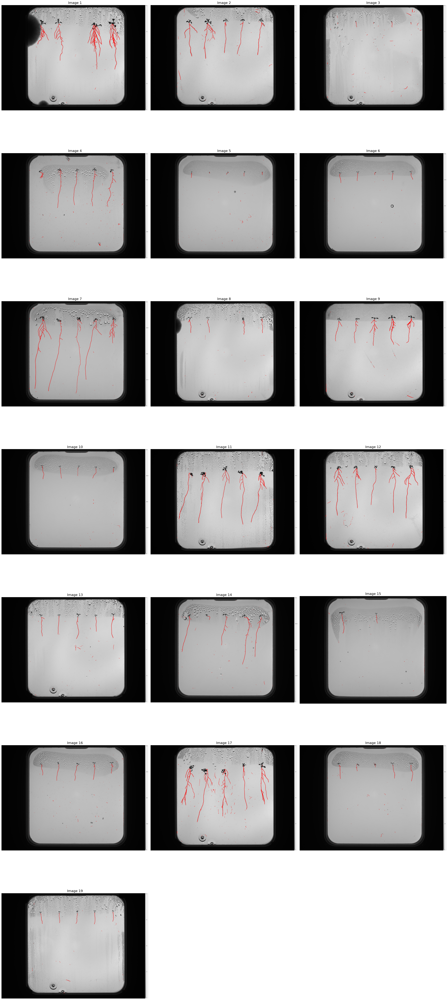

In [11]:
"""
Creates a red overlay of each restored mask on top of its original raw image.
Plots all overlays in a grid to visually confirm alignment across the full dataset.
"""

num_images = len(restored_masks)
cols = 3
rows = math.ceil(num_images / cols)

# Increase figure size per image
plt.figure(figsize=(10 * cols, 10 * rows))

for i in range(num_images):

    print(f"Overlaying image {i+1}: {os.path.basename(test_image_paths[i])}")

    # Load original raw image (grayscale)
    raw_img = cv2.imread(test_image_paths[i], cv2.IMREAD_GRAYSCALE)

    # Convert to RGB so a red mask can be drawn
    raw_rgb = cv2.cvtColor(raw_img, cv2.COLOR_GRAY2RGB)

    # Restored mask (same size as raw image)
    mask = restored_masks[i].astype(np.uint8)

    # Create overlay (root pixels become red)
    overlay = raw_rgb.copy()
    overlay[mask == 1] = [255, 0, 0]

    # Plot overlay in a grid
    plt.subplot(rows, cols, i + 1)
    plt.imshow(overlay)
    plt.title(f"Image {i+1}", fontsize=16)
    plt.axis("off")

plt.tight_layout()
plt.show()


## Post-processing the Restored Root Masks


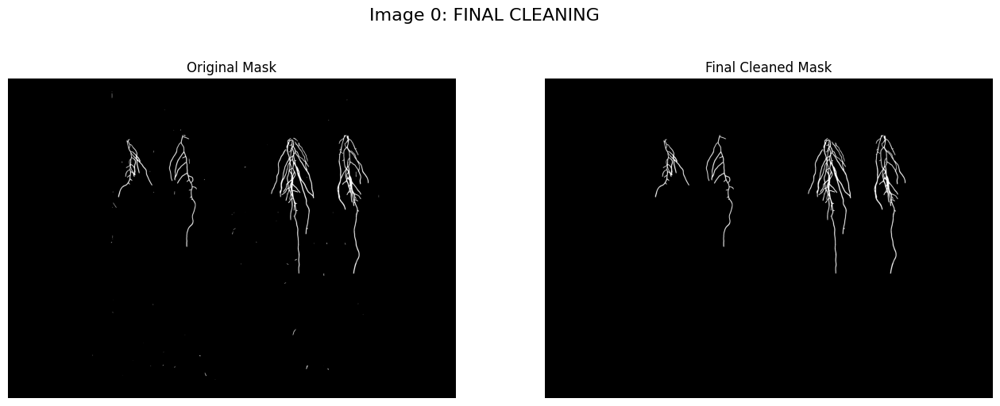

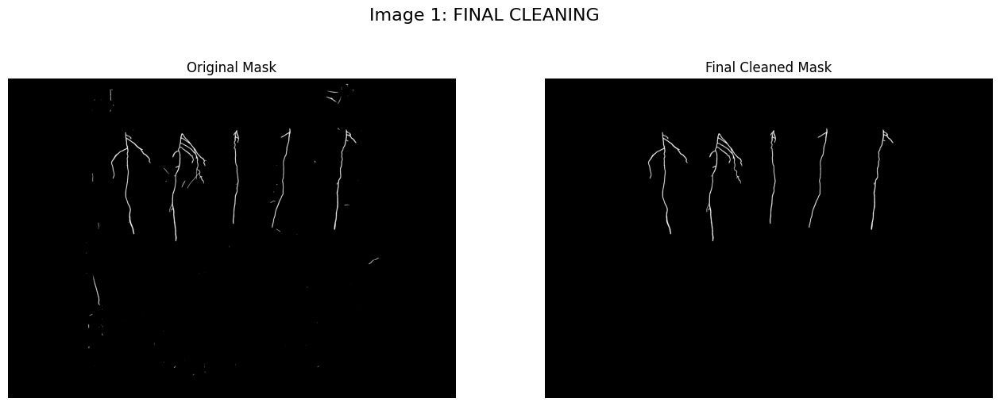

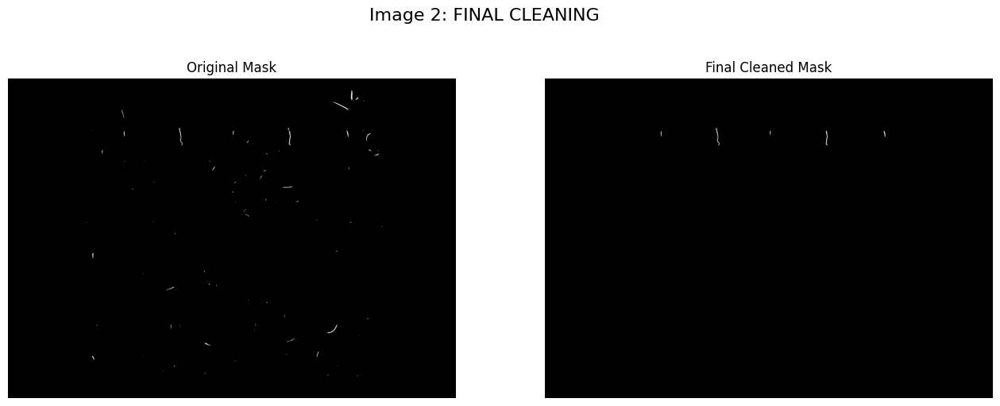

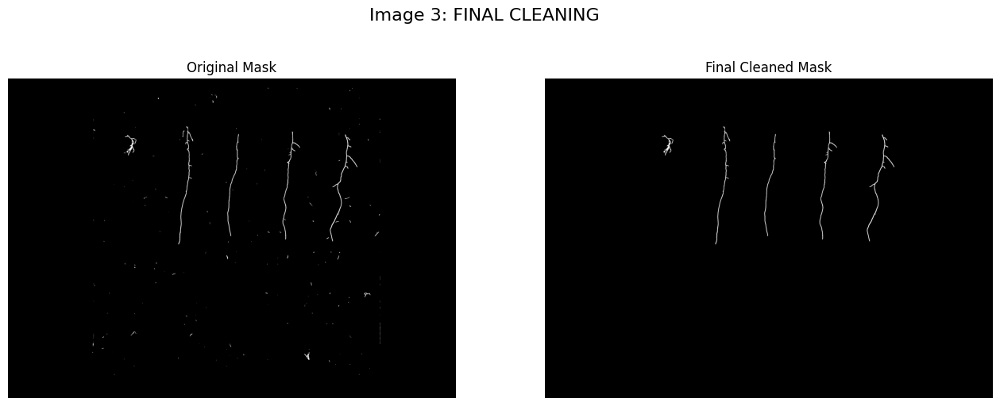

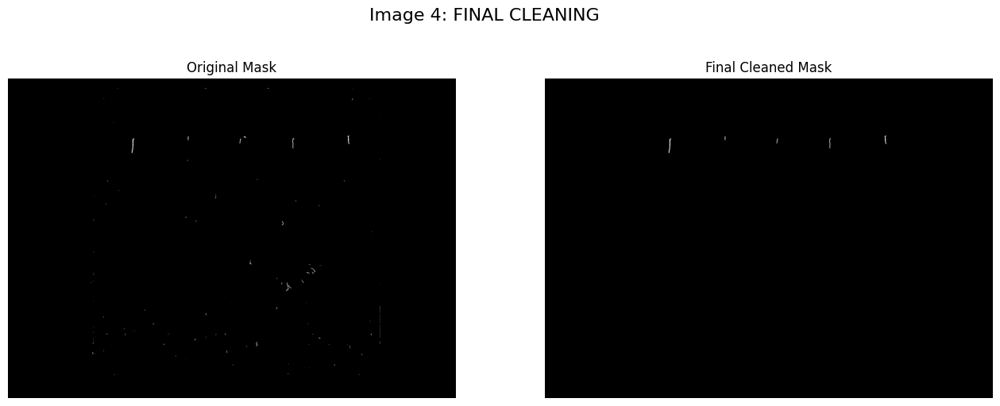

...

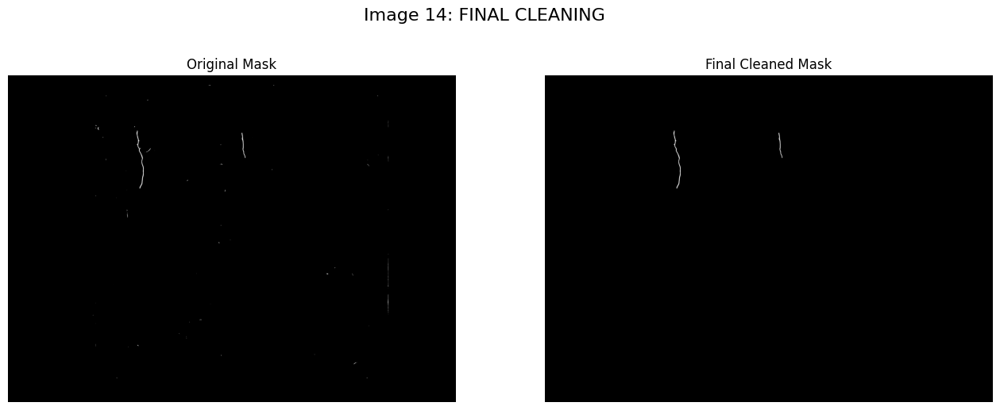

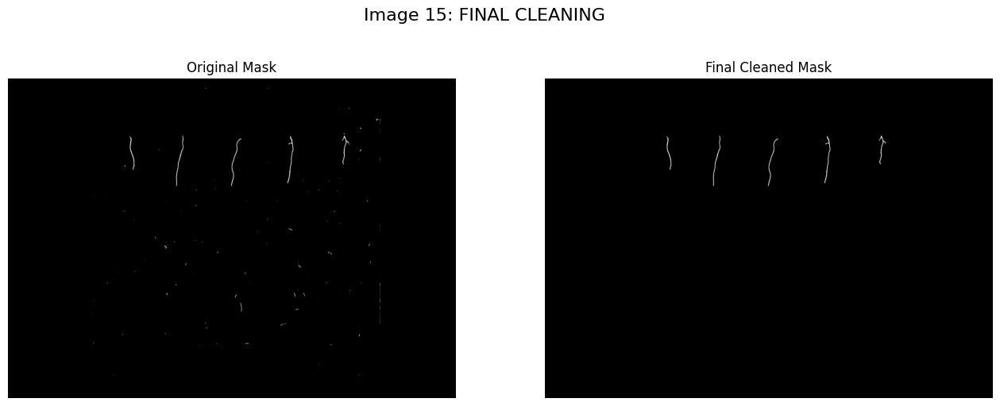

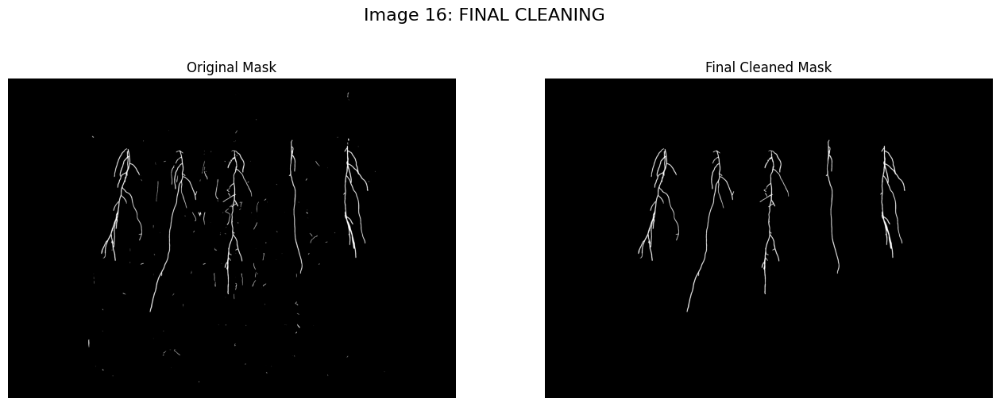

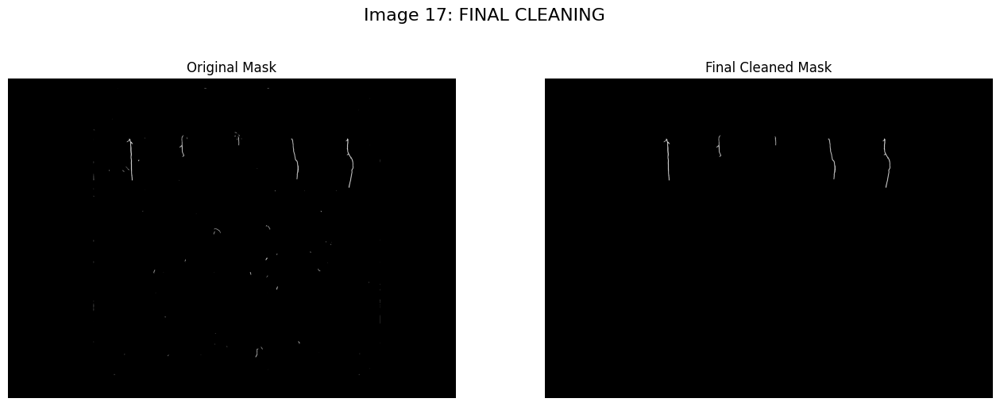

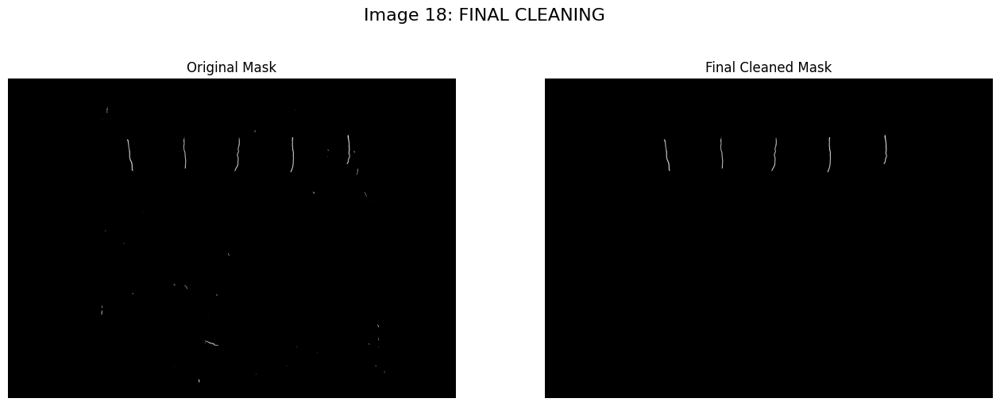

In [12]:
"""
Post-processes the restored masks to remove noise and keep plant-like root structures.

This cell defines several cleaning steps:
1) Find dense bands in X/Y projections to focus on the main root area.
2) Keep only mask pixels inside the main spatial band (with padding + component expansion).
3) Filter components by shape and orientation to keep root-like objects.
4) Apply margin rules (remove top region, remove small side-touching noise).
5) Keep components that start near the crown (drop only small late starters).
6) Extra cleanup: remove small noise close to plants, and remove small isolated components.
Finally, it runs the full pipeline on all restored masks and visualizes before/after results.
"""
# 1) Density band finder

def find_density_band(projection, keep_ratio=0.95):
    """
    Finds the smallest index range that contains keep_ratio of the foreground mass
    in a 1D projection (row/column sums).
    """
    total = projection.sum()
    if total == 0:
        return 0, len(projection) - 1
    cum = np.cumsum(projection)
    low  = np.searchsorted(cum, (1 - keep_ratio) * total)
    high = np.searchsorted(cum, keep_ratio * total)
    return max(0, low), min(len(projection) - 1, high)

# 2) Band-based spatial cleaner

def clean_root_mask(mask, keep_ratio_x=0.93, keep_ratio_y=0.90, padding=40):
    """
    Keeps only the region where most foreground pixels exist (band in X and Y),
    then expands the band if overlapping components extend slightly outside it.
    """
    H, W = mask.shape
    col_sum = mask.sum(axis=0)
    row_sum = mask.sum(axis=1)

    x_min, x_max = find_density_band(col_sum, keep_ratio_x)
    y_min, y_max = find_density_band(row_sum, keep_ratio_y)

    x_min0 = max(0, x_min - padding)
    x_max0 = min(W - 1, x_max + padding)
    y_min0 = max(0, y_min - padding)
    y_max0 = min(H - 1, y_max + padding)

    lbl = label(mask)
    regions = regionprops(lbl)

    # Expand the band to include components that overlap the band
    for r in regions:
        xmin, ymin, xmax, ymax = r.bbox[1], r.bbox[0], r.bbox[3], r.bbox[2]
        horizontal_overlap = not (xmax < x_min0 or xmin > x_max0)
        vertical_overlap   = not (ymax < y_min0 or ymin > y_max0)
        if horizontal_overlap and vertical_overlap:
            x_min0 = min(x_min0, xmin - padding)
            x_max0 = max(x_max0, xmax + padding)
            y_min0 = min(y_min0, ymin - padding)
            y_max0 = max(y_max0, ymax + padding)

    x_min0 = max(0, x_min0)
    x_max0 = min(W - 1, x_max0)
    y_min0 = max(0, y_min0)
    y_max0 = min(H - 1, y_max0)

    cleaned = np.zeros_like(mask)
    cleaned[y_min0:y_max0, x_min0:x_max0] = mask[y_min0:y_max0, x_min0:x_max0]
    return cleaned

# 3) Orientation + shape filtering

def orientation_filter(mask, angle_limit=40, aspect_limit=1.2, ecc_limit=0.5, skel_limit=3):
    """
    Keeps components that look like long root structures using:
    - orientation angle
    - aspect ratio (major/minor axis)
    - eccentricity
    - skeleton length
    """
    labeled = label(mask)
    output = np.zeros_like(mask)

    for region in regionprops(labeled):
        comp = (labeled == region.label)

        ecc = region.eccentricity
        maj = region.major_axis_length
        minr = region.minor_axis_length + 1e-5
        aspect = maj / minr
        skel_len = skeletonize(comp).sum()

        angle = abs(region.orientation * 180 / np.pi)
        angle = min(angle, 180 - angle)

        if (
            angle <= angle_limit and
            aspect >= aspect_limit and
            ecc >= ecc_limit and
            skel_len >= skel_limit
        ):
            output[comp] = 1

    return output

# 4) Hard top + side margins (remove only small side-touching comps)

def margin_clean(mask, top_frac=0.15, side_px=840, side_small_area=500):
    """
    Removes:
    - Everything in the top top_frac of the image
    - Only small components that touch the left/right side margins
    """
    H, W = mask.shape
    out = mask.copy()

    top_cut = int(top_frac * H)
    out[:top_cut, :] = 0

    lbl = label(out)
    for r in regionprops(lbl):
        minr, minc, maxr, maxc = r.bbox
        touches_left  = (minc < side_px)
        touches_right = (maxc > (W - side_px))

        if (touches_left or touches_right) and (r.area < side_small_area):
            out[lbl == r.label] = 0

    return out

# 5) Keep components near crown start (drop only small late starters)

def keep_components_near_top_start(mask, expected_plants=5, start_slack_px=80, late_small_area=2000):
    """
    Estimates crown_y from the top-starting components.
    Keeps components starting near the crown, and removes only small late-starting noise.
    """
    lbl = label(mask)
    regions = regionprops(lbl)
    if not regions:
        return mask

    starts = sorted([(r.bbox[0], r.label) for r in regions], key=lambda x: x[0])
    k = min(expected_plants, len(starts))
    crown_y = max(s for s, _ in starts[:k])
    threshold_y = crown_y + start_slack_px

    out = np.zeros_like(mask)

    for r in regions:
        comp = (lbl == r.label)
        minr = r.bbox[0]

        if minr <= threshold_y:
            out[comp] = 1
            continue

        if r.area >= late_small_area:
            out[comp] = 1

    return out
# 6) Remove small components close to plants (distance-based)

def remove_small_close_to_plants(mask, plant_count=5, small_area=500, near_px=40):
    """
    Treats the largest plant_count components as plants.
    Removes any other small component that lies within near_px of a plant.
    """
    lbl = label(mask)
    regions = regionprops(lbl)
    if not regions:
        return mask

    regions_sorted = sorted(regions, key=lambda r: r.area, reverse=True)
    plants = regions_sorted[:min(plant_count, len(regions_sorted))]

    plant_mask = np.zeros_like(mask, dtype=bool)
    plant_labels = set()
    for r in plants:
        plant_mask[lbl == r.label] = True
        plant_labels.add(r.label)

    if not plant_mask.any():
        return mask

    dist_to_plant = distance_transform_edt(~plant_mask)

    out = mask.copy()
    for r in regions:
        if r.label in plant_labels:
            continue
        if r.area >= small_area:
            continue

        comp = (lbl == r.label)
        if dist_to_plant[comp].min() <= near_px:
            out[comp] = 0

    return out

# 7) Remove small isolated components

def remove_small_isolated(mask, small_area=800, isolation_px=150):
    """
    Removes small components that are far away from all other foreground pixels.
    """
    lbl = label(mask)
    regions = regionprops(lbl)
    if len(regions) <= 1:
        return mask

    out = mask.copy()

    for r in regions:
        if r.area >= small_area:
            continue

        comp = (lbl == r.label)
        others = mask & (~comp)
        if not others.any():
            continue

        dist = distance_transform_edt(~others)
        if dist[comp].min() >= isolation_px:
            out[comp] = 0

    return out

# RUN FULL PIPELINE + VISUALIZE

all_cleaned_masks_final = []

for i, rm in enumerate(restored_masks):

    band_cleaned = clean_root_mask(rm)
    oriented = orientation_filter(band_cleaned)
    margined = margin_clean(oriented, top_frac=0.15, side_px=840, side_small_area=500)

    cleaned = keep_components_near_top_start(
        margined,
        expected_plants=5,
        start_slack_px=80,
        late_small_area=2000
    )

    cleaned = remove_small_close_to_plants(
        cleaned,
        plant_count=5,
        small_area=1000,
        near_px=800
    )

    cleaned = remove_small_isolated(
        cleaned,
        small_area=200,
        isolation_px=150
    )

    all_cleaned_masks_final.append(cleaned)

    plt.figure(figsize=(16, 6))
    plt.suptitle(f"Image {i}: FINAL CLEANING", fontsize=16)

    plt.subplot(1, 2, 1)
    plt.imshow(rm, cmap="gray")
    plt.title("Original Mask")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cleaned, cmap="gray")
    plt.title("Final Cleaned Mask")
    plt.axis("off")

    plt.show()


## Separation of Roots into Individual Plants(Task 6)


GLOBAL centers: [1122, 1642, 2168, 2668, 3185]
GLOBAL corridor: (1106, 3203)


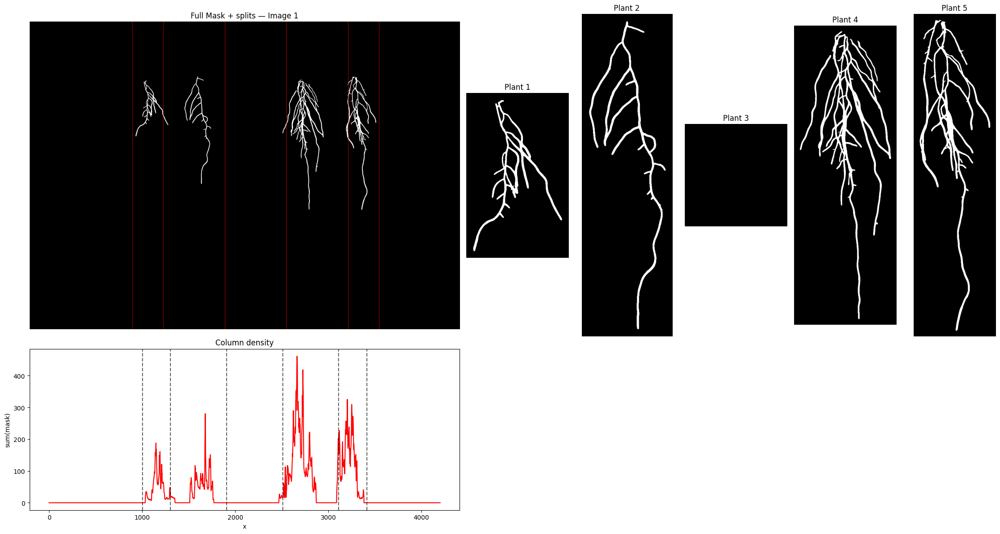

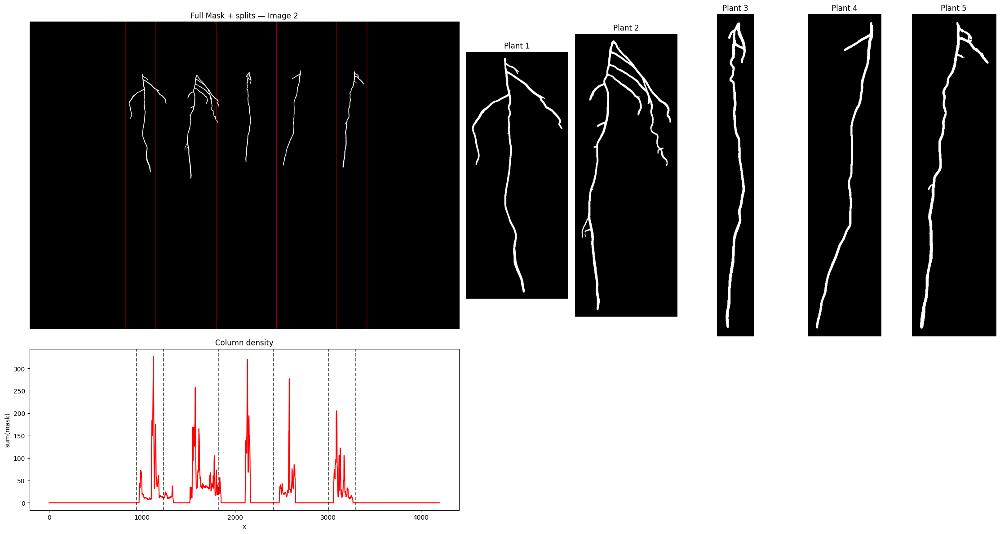

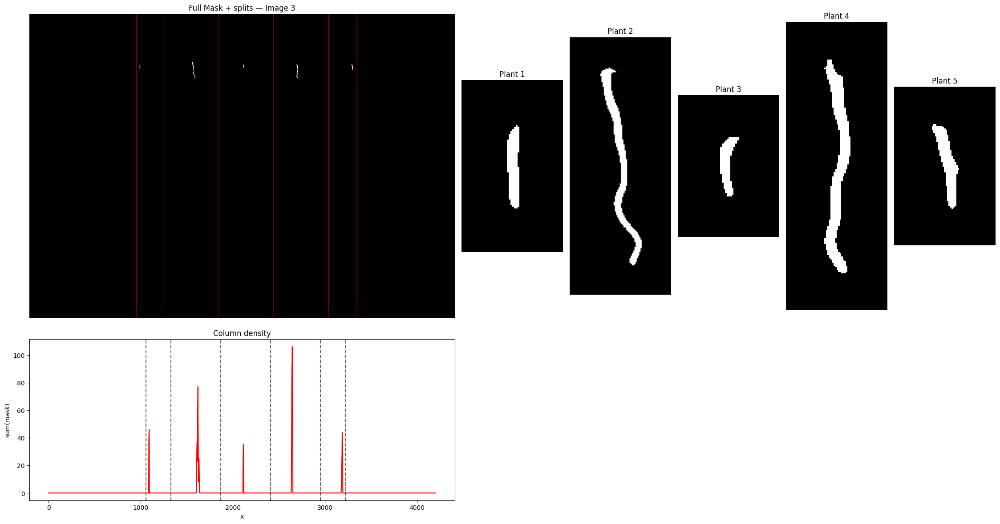

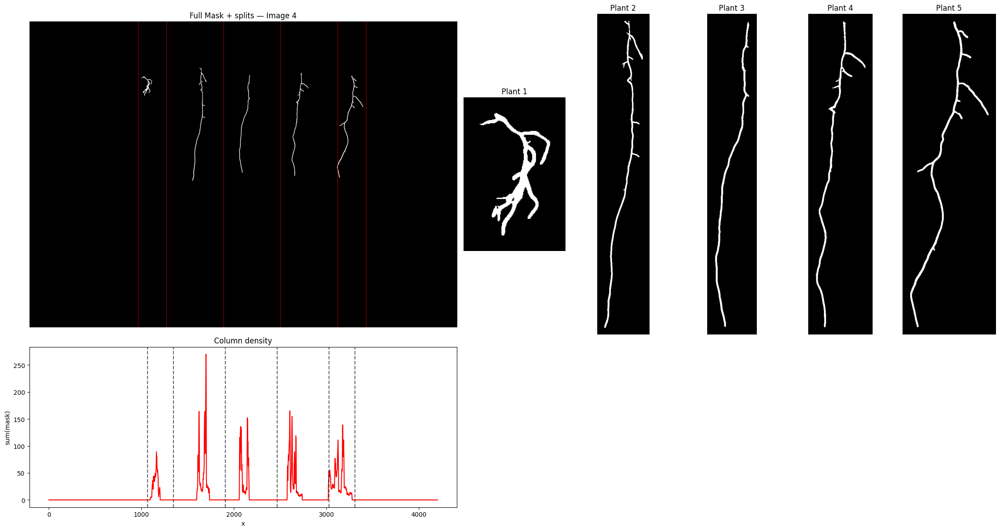

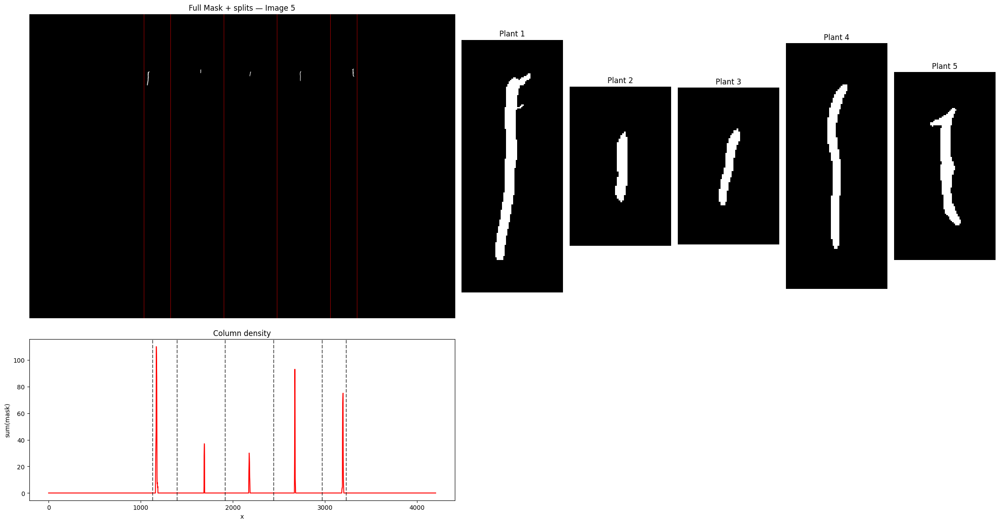

...

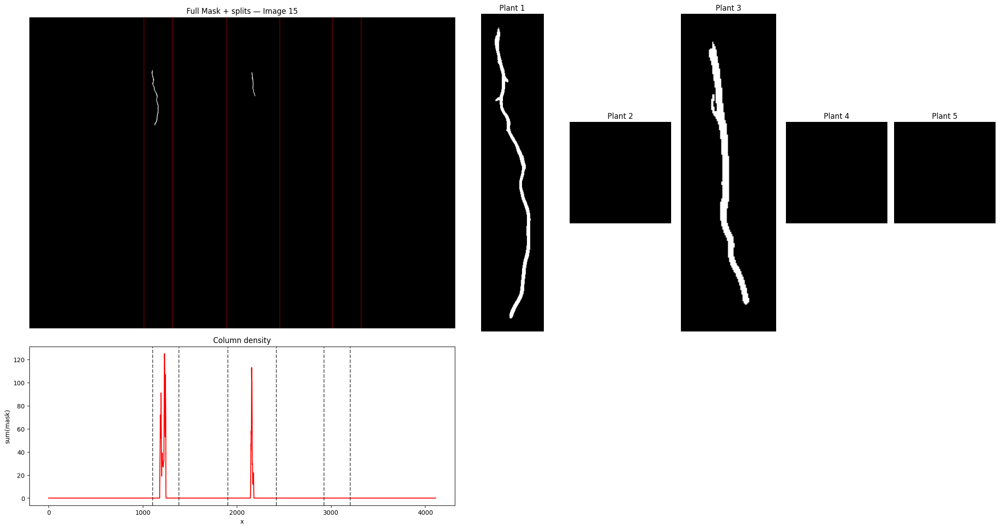

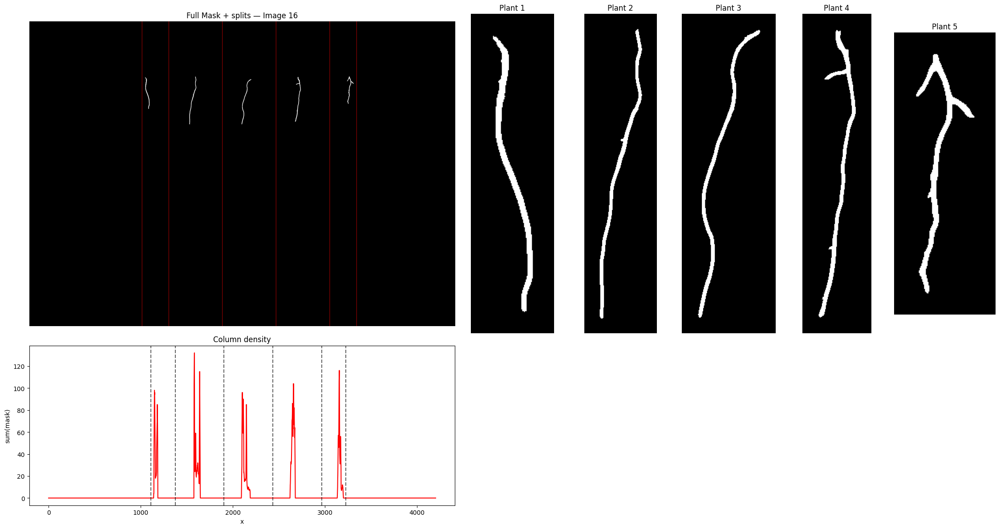

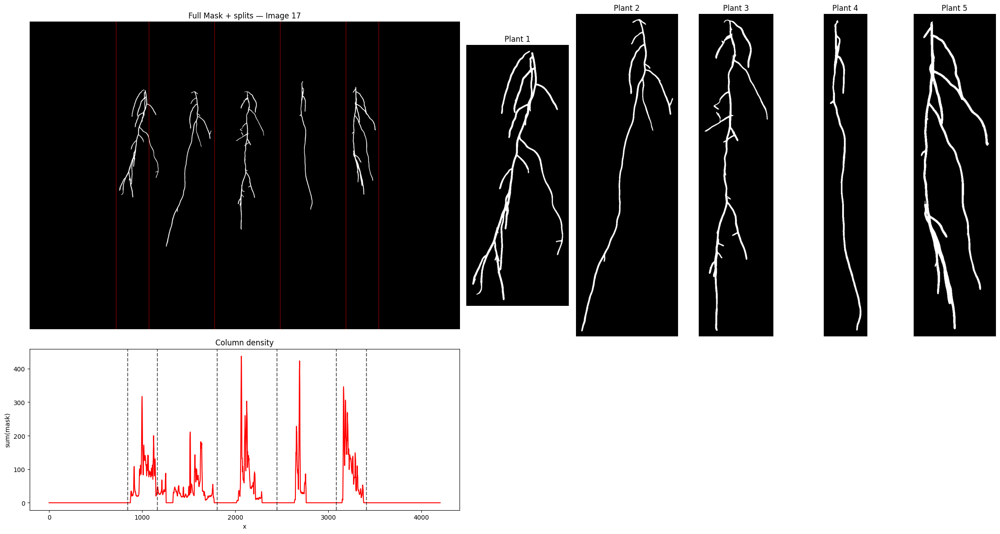

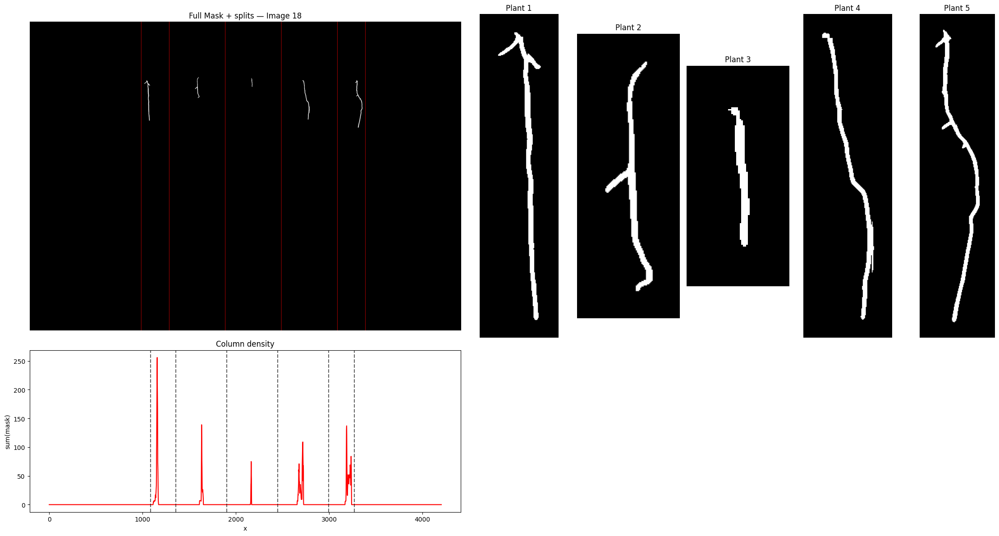

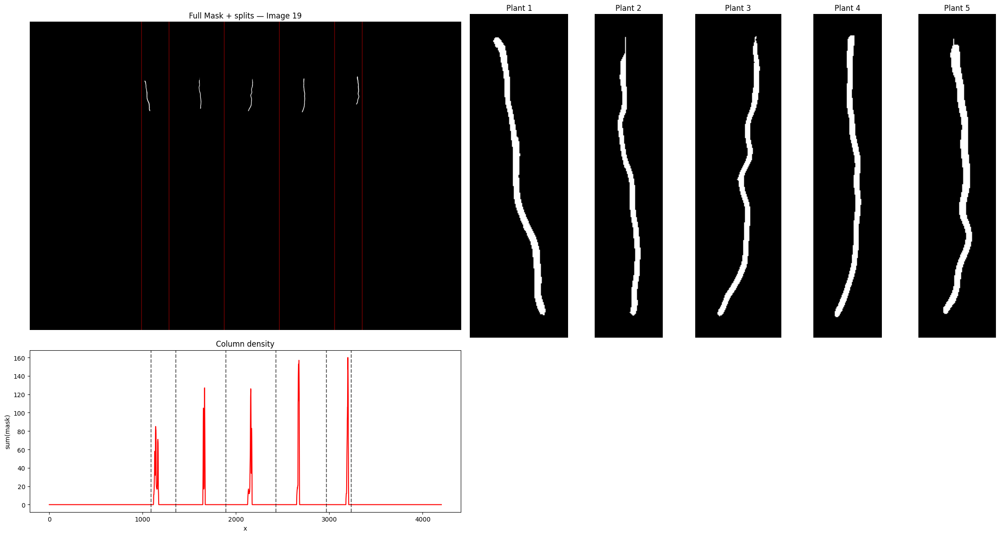

In [13]:
"""
Task 6: Split each cleaned full-image root mask into 5 individual plant masks.

Pipeline:
1) Detect the root corridor using column-density (foreground pixel sums).
2) Split the corridor into 5 fixed lanes (bounds + centers).
3) Assign each connected component to the nearest lane center.
4) Learn stable GLOBAL lane centers from all images (excluding a chosen fallback index).
5) Visualize: full mask with split lines + 5 plant crops + column-density plot.
"""

# 1) Corridor detection (x-limits from column density)

def find_corridor_x_limits(mask01, min_col_pixels=3, pad=30, fallback_frac=(0.20, 0.80)):
    """
    Finds left/right x-limits of the main root corridor using column sums.
    If no corridor is detected, uses a fallback fraction of image width.
    """
    m = (mask01 > 0).astype(np.uint8)
    H, W = m.shape

    col = m.sum(axis=0)
    xs = np.where(col >= min_col_pixels)[0]

    if len(xs) == 0:
        xL = int(fallback_frac[0] * W)
        xR = int(fallback_frac[1] * W)
        return xL, xR, col

    xL = max(0, int(xs.min()) - pad)
    xR = min(W - 1, int(xs.max()) + pad)
    return xL, xR, col

# 2) Split into 5 corridor slots + assign components by nearest center

def split_corridor_into_5(mask01, min_obj_size=15, min_col_pixels=3, pad=30):
    """
    Cleans small noise, finds corridor limits, creates 5 lane centers,
    and assigns each connected component to the nearest lane.
    """
    m = (mask01 > 0).astype(np.uint8)
    m = remove_small_objects(m.astype(bool), min_size=min_obj_size).astype(np.uint8)

    H, W = m.shape

    xL, xR, col = find_corridor_x_limits(m, min_col_pixels=min_col_pixels, pad=pad)
    xL = int(np.clip(xL, 0, W - 2))
    xR = int(np.clip(xR, xL + 1, W - 1))

    centers = np.linspace(xL, xR, 5).astype(int).tolist()

    bounds = [xL]
    for i in range(4):
        bounds.append((centers[i] + centers[i + 1]) // 2)
    bounds.append(xR)

    lbl = label(m, connectivity=2)
    regs = regionprops(lbl)

    slot_masks = [np.zeros_like(m, dtype=np.uint8) for _ in range(5)]
    for r in regs:
        _, cx = r.centroid
        cx = float(cx)
        slot = int(np.argmin([abs(cx - c) for c in centers]))
        slot_masks[slot][lbl == r.label] = 1

    return slot_masks, bounds, centers, (xL, xR), col

# 3) Stable crown-x (top-start x) for better lane assignment

def crown_x(region):
    """
    Returns a stable x-position near the top of a component (crown position).
    """
    coords = region.coords  # (N,2): y,x
    ymin = coords[:, 0].min()
    xs = coords[coords[:, 0] == ymin][:, 1]
    return float(np.median(xs)) if len(xs) else float(region.centroid[1])

# 4) Learn GLOBAL lane centers from other images (fallback helper)

def learn_global_centers(masks01, exclude_idx_1based=15, expected=5):
    """
    Uses images != exclude_idx to learn stable plant x-centers.
    If not enough data, falls back to evenly spaced centers.
    """
    H, W = masks01[0].shape
    per_rank = [[] for _ in range(expected)]
    mins, maxs = [], []

    for i, m in enumerate(masks01, start=1):
        if i == exclude_idx_1based:
            continue

        mm = (m > 0).astype(np.uint8)
        lbl = label(mm, connectivity=2)
        regs = regionprops(lbl)

        xs = []
        for r in regs:
            if r.area < 15:
                continue
            xs.append(crown_x(r))

        xs = sorted(xs)
        if len(xs) >= expected:
            for k in range(expected):
                per_rank[k].append(xs[k])

        if len(xs) > 0:
            mins.append(xs[0])
            maxs.append(xs[-1])

    if min(len(v) for v in per_rank) >= 3:
        centers = [float(np.median(per_rank[k])) for k in range(expected)]
    else:
        centers = np.linspace(0.2 * W, 0.8 * W, expected).tolist()

    centers = sorted(centers)

    if len(mins) >= 3 and len(maxs) >= 3:
        xL = int(np.percentile(mins, 10))
        xR = int(np.percentile(maxs, 90))
    else:
        xL = int(0.2 * W)
        xR = int(0.8 * W)

    xL = int(np.clip(xL, 0, W - 2))
    xR = int(np.clip(xR, xL + 1, W - 1))

    bounds = [xL]
    for i in range(4):
        b = int(round(0.5 * (centers[i] + centers[i + 1])))
        bounds.append(int(np.clip(b, xL, xR)))
    bounds.append(xR)

    return centers, bounds, (xL, xR)

# 5) Fallback splitter using GLOBAL centers

def assign_slots_using_global_centers(full_mask01, global_centers, global_bounds, global_corridor):
    """
    Assigns connected components to the nearest global lane center.
    Useful when corridor detection fails or collapses.
    """
    m = (full_mask01 > 0).astype(np.uint8)
    col = m.sum(axis=0)

    lbl = label(m, connectivity=2)
    regs = regionprops(lbl)

    slot_masks = [np.zeros_like(m, dtype=np.uint8) for _ in range(5)]

    for r in regs:
        cx = crown_x(r)
        slot = int(np.argmin([abs(cx - c) for c in global_centers]))
        slot_masks[slot][lbl == r.label] = 1

    return slot_masks, global_bounds, global_centers, global_corridor, col



# 6) Visualization helpers

def crop_mask(mask, pad=25):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return np.zeros((200, 200), dtype=np.uint8)
    return mask[
        max(0, ys.min() - pad):min(mask.shape[0], ys.max() + pad),
        max(0, xs.min() - pad):min(mask.shape[1], xs.max() + pad)
    ]

def show_corridor_style(mask01, slot_masks, bounds, col, idx):
    """
    Shows: full mask with lane bounds, each plant crop, and the column density plot.
    """
    m = (mask01 > 0).astype(np.uint8)

    fig = plt.figure(figsize=(25, 12))
    gs = fig.add_gridspec(2, 10, height_ratios=[8, 4])

    ax0 = fig.add_subplot(gs[0, :4])
    vis = cv2.cvtColor(m * 255, cv2.COLOR_GRAY2BGR)
    for b in bounds:
        cv2.line(vis, (int(b), 0), (int(b), m.shape[0] - 1), (0, 0, 255), 2)
    ax0.imshow(vis[..., ::-1])
    ax0.set_title(f"Full Mask + splits — Image {idx}")
    ax0.axis("off")

    for i in range(5):
        ax = fig.add_subplot(gs[0, 4 + i])
        ax.imshow(crop_mask(slot_masks[i]), cmap="gray")
        ax.set_title(f"Plant {i+1}")
        ax.axis("off")

    axp = fig.add_subplot(gs[1, :4])
    axp.plot(col, color="red")
    for b in bounds:
        axp.axvline(int(b), color="k", ls="--", alpha=0.6)
    axp.set_title("Column density")
    axp.set_xlabel("x")
    axp.set_ylabel("sum(mask)")

    plt.tight_layout()
    plt.show()
    plt.close(fig)

# 7) RUN TASK 6 ON ALL IMAGES + VISUALIZE

FALLBACK_INDEX_1BASED = 15

GLOBAL_CENTERS, GLOBAL_BOUNDS, GLOBAL_CORRIDOR = learn_global_centers(
    all_cleaned_masks_final,
    exclude_idx_1based=FALLBACK_INDEX_1BASED,
    expected=5
)

print("GLOBAL centers:", [int(c) for c in GLOBAL_CENTERS])
print("GLOBAL corridor:", GLOBAL_CORRIDOR)

all_slot_masks = []
all_bounds = []
all_centers = []
all_corridors = []

for idx, full_mask in enumerate(all_cleaned_masks_final, start=1):

    if idx == FALLBACK_INDEX_1BASED:
        slot_masks, bounds, centers, corridor, col = assign_slots_using_global_centers(
            full_mask,
            GLOBAL_CENTERS,
            GLOBAL_BOUNDS,
            GLOBAL_CORRIDOR
        )
    else:
        slot_masks, bounds, centers, corridor, col = split_corridor_into_5(
            full_mask,
            min_obj_size=15,
            min_col_pixels=3,
            pad=30
        )

    all_slot_masks.append(slot_masks)
    all_bounds.append(bounds)
    all_centers.append(centers)
    all_corridors.append(corridor)

    show_corridor_style(full_mask, slot_masks, bounds, col, idx)


## Task 7 — Primary Root Extraction and Length Measurement 

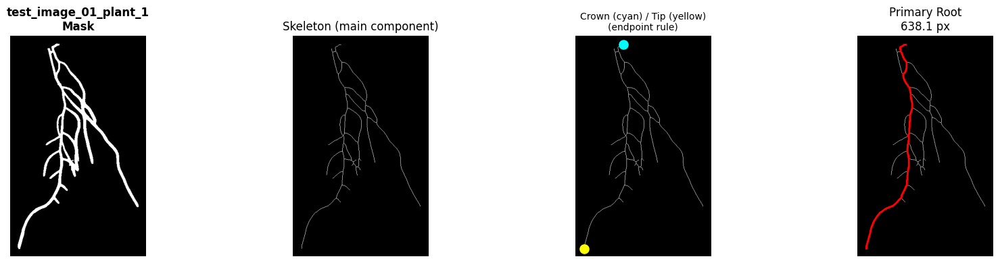

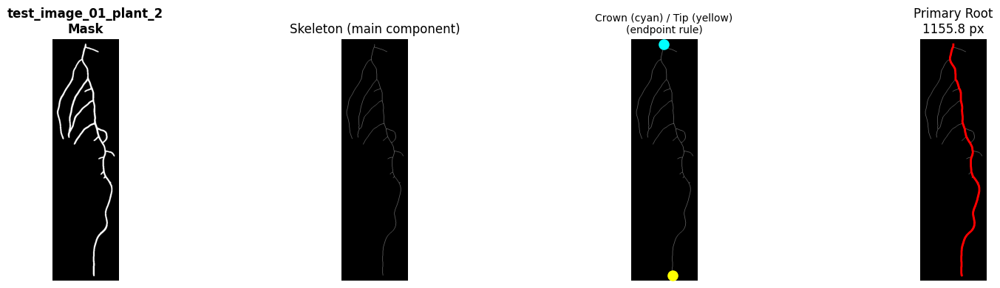

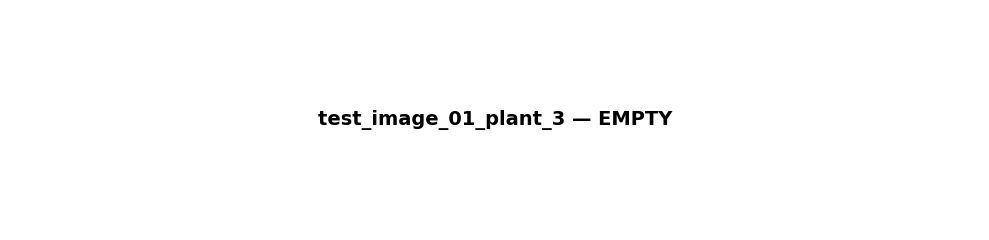

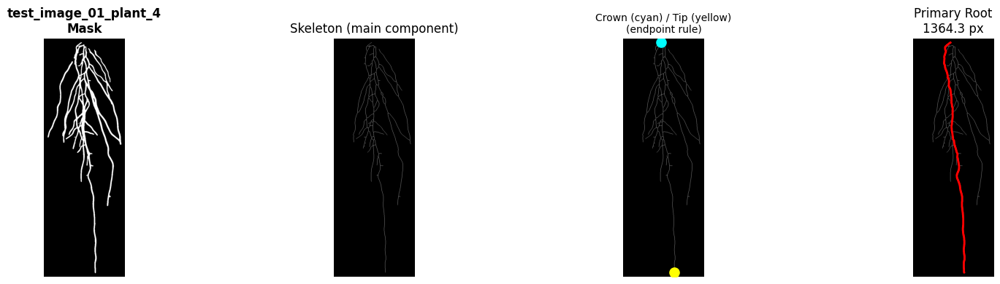

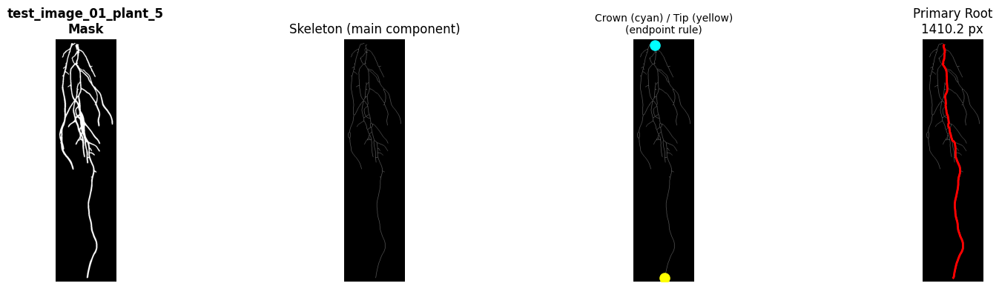

...

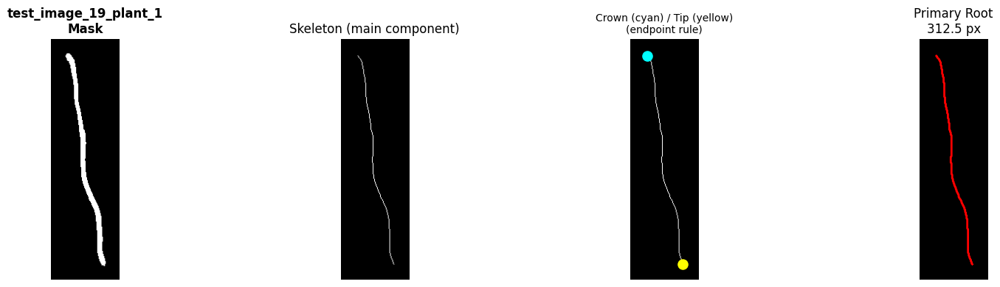

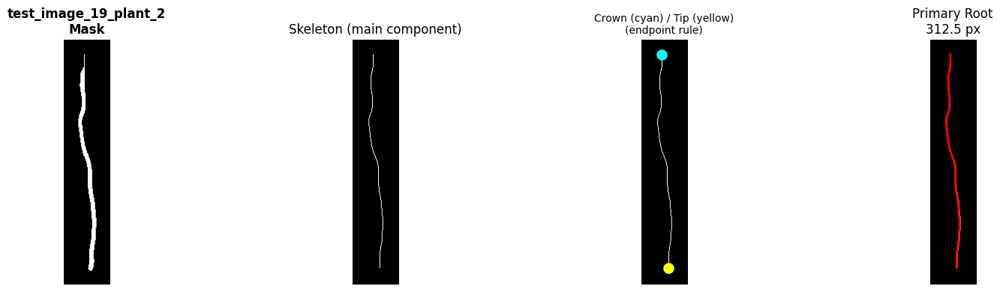

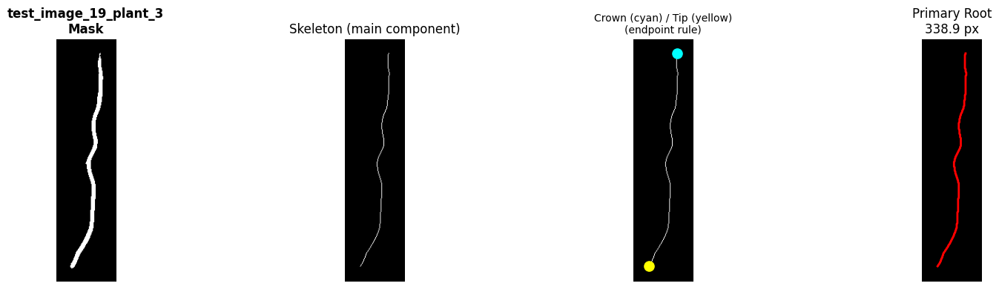

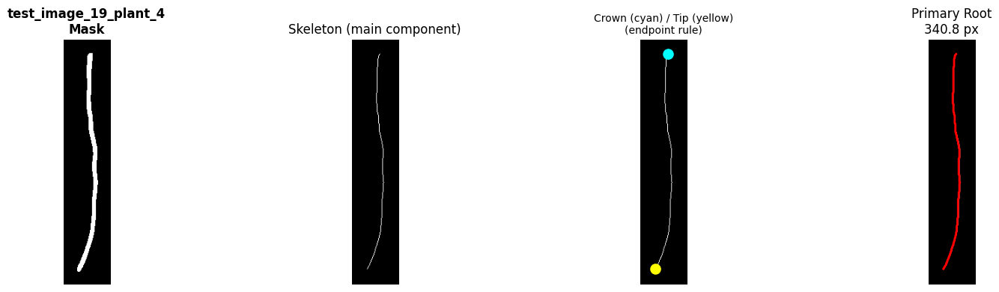

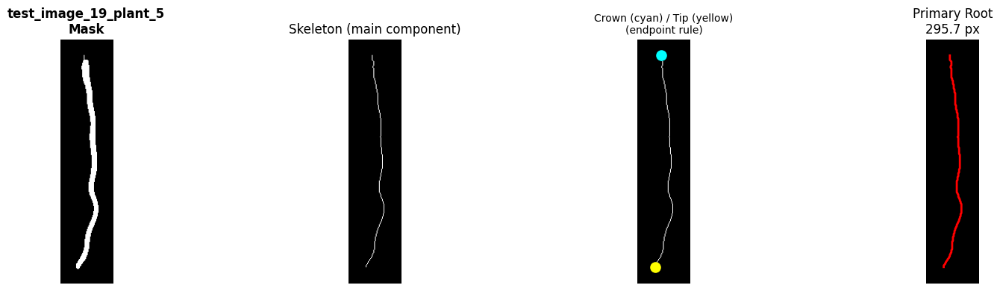

completed. Total predictions: 95
                Plant ID  Length (px)
0  test_image_01_plant_1   638.073160
1  test_image_01_plant_2  1155.766594
2  test_image_01_plant_3     0.000000
3  test_image_01_plant_4  1364.298557
4  test_image_01_plant_5  1410.151370


In [14]:
"""
Task 7: Extracts the primary root for each plant mask and measures its length in pixels.

This cell:
1) Skeletonizes each plant mask.
2) Keeps the main skeleton component (largest/most vertical).
3) Builds a pixel graph from the skeleton (8-neighborhood).
4) Finds the tip (bottom-most endpoint) and crown (top endpoint rule with scoring).
5) Computes the shortest path between crown and tip and sums geometric edge lengths.
6) Saves per-plant root length and tip coordinates, and optionally visualizes results.
"""
# Graph + geometry helpers

def crop_to_bbox(mask, pad=20):
    """Crops a mask to its bounding box (with padding) for clearer visualization."""
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return None, None
    y0, y1 = ys.min(), ys.max()
    x0, x1 = xs.min(), xs.max()
    y0 = max(0, y0 - pad); x0 = max(0, x0 - pad)
    y1 = min(mask.shape[0], y1 + pad); x1 = min(mask.shape[1], x1 + pad)
    return (slice(y0, y1), slice(x0, x1)), (y0, x0)

def build_undirected_graph_from_skel(skel):
    """Builds an undirected weighted graph where each skeleton pixel is a node."""
    ys, xs = np.where(skel)
    G = nx.Graph()
    for y, x in zip(ys, xs):
        G.add_node((y, x))
    for y, x in zip(ys, xs):
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if dy == 0 and dx == 0:
                    continue
                ny, nx_ = y + dy, x + dx
                if (ny, nx_) in G:
                    G.add_edge((y, x), (ny, nx_), w=float(np.hypot(dy, dx)))
    return G

def path_geom_length(G, path):
    """Computes geometric length of a path by summing weighted edges."""
    if path is None or len(path) < 2:
        return 0.0
    return float(sum(G[a][b]["w"] for a, b in zip(path[:-1], path[1:])))

def pick_main_component_skeleton(skel_full, min_component_nodes=40):
    """Selects the most relevant skeleton component (prefer tall + large)."""
    lab = label(skel_full, connectivity=2)
    if lab.max() == 0:
        return None

    best_lab = None
    best_key = None
    for k in range(1, lab.max() + 1):
        ys, xs = np.where(lab == k)
        if len(xs) < min_component_nodes:
            continue
        key = (int(ys.max() - ys.min()), int(len(xs)))  # (vertical extent, size)
        if best_key is None or key > best_key:
            best_key = key
            best_lab = k

    if best_lab is None:
        best_lab = max(range(1, lab.max() + 1), key=lambda k: int(np.sum(lab == k)))

    return (lab == best_lab)

def endpoints_of_graph(G):
    """Returns graph nodes with degree 1 (endpoints)."""
    deg = dict(G.degree())
    return [n for n, d in deg.items() if d == 1]

def euclid(p, q):
    """Euclidean distance between two (y,x) points."""
    return float(np.hypot(p[0] - q[0], p[1] - q[1]))

# Tip selection (bottommost endpoint)

def pick_tip_bottom_endpoint(G):
    """Selects the tip as the endpoint with the largest y (lowest in the image)."""
    eps = endpoints_of_graph(G)
    if not eps:
        return None

    max_y = max(y for (y, x) in eps)
    bottom = [n for n in eps if n[0] == max_y]
    if len(bottom) == 1:
        return bottom[0]

    xs = sorted([x for (y, x) in bottom])
    x_med = xs[len(xs)//2]
    return min(bottom, key=lambda n: abs(n[1] - x_med))

# Branchiness proxy

def first_junction_degree(G, endpoint, max_steps=2000):
    """
    Walks inward from an endpoint until a junction (degree != 2) is found.
    Returns that junction degree (higher implies more branching).
    """
    if endpoint not in G:
        return 0
    if G.degree[endpoint] != 1:
        return int(G.degree[endpoint])

    prev = None
    cur = endpoint
    steps = 0

    while steps < max_steps:
        steps += 1
        nbs = list(G.neighbors(cur))
        if prev is not None:
            nbs = [n for n in nbs if n != prev]
        if not nbs:
            return int(G.degree[cur])

        nxt = nbs[0]
        prev, cur = cur, nxt

        d = int(G.degree[cur])
        if d != 2:
            return d

    return 2

# Crown selection (endpoint-based rule + scoring)
def pick_crown_by_your_rule(G, mask, tip, top_band_px=3, close_radius_px=12):
    """
    Picks the crown among top endpoints using:
    - thickness (distance transform)
    - x-alignment with tip
    - branchiness (first junction degree)
    - preference for highest y
    """
    eps = endpoints_of_graph(G)
    if not eps:
        return None

    # Keep only endpoints connected to the tip (avoid stray components)
    try:
        dist_from_tip = nx.single_source_dijkstra_path_length(G, tip, weight="w")
        eps = [e for e in eps if e in dist_from_tip]
    except Exception:
        pass

    if not eps:
        return None

    min_y = min(e[0] for e in eps)
    highest_eps = [e for e in eps if e[0] <= min_y + top_band_px]

    if len(highest_eps) == 1:
        h = highest_eps[0]
        close_any = any(euclid(h, e) <= close_radius_px for e in eps if e != h)
        if not close_any:
            return h

    cand = highest_eps if len(highest_eps) >= 2 else sorted(eps, key=lambda e: e[0])[:10]
    dt = distance_transform_edt(mask > 0)
    tip_x = tip[1]

    best = None
    best_score = None

    for e in cand:
        thick = float(dt[e[0], e[1]])
        x_align = abs(e[1] - tip_x)
        jdeg = float(first_junction_degree(G, e))

        score = (
            20.0 * thick
            + 30.0 * jdeg
            - 2.5 * x_align
            - 0.5 * (e[0] - min_y)
        )

        if best_score is None or score > best_score:
            best_score = score
            best = e

    return best

# Full extractor

def extract_primary_root_task7(mask, min_pixels=50, min_component_nodes=40, top_band_px=3, close_radius_px=12):
    """Extracts primary root skeleton path and returns crown, tip, and length."""
    if mask.sum() < min_pixels:
        return None, None, None, None, 0.0, None

    skel_full = skeletonize(mask > 0)
    if skel_full.sum() < 10:
        return skel_full, None, None, None, 0.0, None

    skel = pick_main_component_skeleton(skel_full, min_component_nodes=min_component_nodes)
    if skel is None or skel.sum() < 10:
        return skel_full, None, None, None, 0.0, None

    G = build_undirected_graph_from_skel(skel)
    if G.number_of_nodes() < 10:
        return skel, None, None, None, 0.0, G

    tip = pick_tip_bottom_endpoint(G)
    if tip is None:
        return skel, None, None, None, 0.0, G

    crown = pick_crown_by_your_rule(G, mask, tip, top_band_px=top_band_px, close_radius_px=close_radius_px)
    if crown is None:
        return skel, None, tip, None, 0.0, G

    try:
        path = nx.shortest_path(G, crown, tip, weight="w")
        length = path_geom_length(G, path)
    except nx.NetworkXNoPath:
        path, length = None, 0.0

    return skel, crown, tip, path, float(length), G

# RUN TASK 7 + VISUALIZE

MIN_PIXELS = 50
MIN_COMPONENT_NODES = 40
CROP_PAD = 20
SHOW_VIZ = True

TOP_BAND_PX = 3
CLOSE_RADIUS_PX = 12

records = []
tip_records = []

for img_idx, plant_masks in enumerate(all_slot_masks, start=1):
    for plant_idx, mask in enumerate(plant_masks, start=1):
        plant_id = f"test_image_{img_idx:02d}_plant_{plant_idx}"

        skel, crown, tip, path, length, G = extract_primary_root_task7(
            mask,
            min_pixels=MIN_PIXELS,
            min_component_nodes=MIN_COMPONENT_NODES,
            top_band_px=TOP_BAND_PX,
            close_radius_px=CLOSE_RADIUS_PX
        )

        records.append({"Plant ID": plant_id, "Length (px)": float(length)})

        if tip is None:
            tip_x, tip_y = np.nan, np.nan
        else:
            tip_y, tip_x = tip
        tip_records.append({"Plant ID": plant_id, "Tip X": tip_x, "Tip Y": tip_y})

        if not SHOW_VIZ:
            continue

        if skel is None:
            fig, ax = plt.subplots(1, 1, figsize=(10, 2.5))
            ax.text(0.5, 0.5, f"{plant_id} — EMPTY", ha="center", va="center",
                    fontsize=14, weight="bold")
            ax.axis("off")
            plt.tight_layout()
            plt.show()
            continue

        crop_slice, (y0, x0) = crop_to_bbox(mask, pad=CROP_PAD)
        m_crop = mask[crop_slice] if crop_slice else mask
        s_crop = skel[crop_slice] if crop_slice else skel

        fig, axes = plt.subplots(1, 4, figsize=(18, 4))

        axes[0].imshow(m_crop, cmap="gray")
        axes[0].set_title(f"{plant_id}\nMask", fontsize=12, weight="bold")
        axes[0].axis("off")

        axes[1].imshow(s_crop, cmap="gray")
        axes[1].set_title("Skeleton (main component)", fontsize=12)
        axes[1].axis("off")

        axes[2].imshow(s_crop, cmap="gray")
        if crown is not None:
            axes[2].scatter(crown[1] - x0, crown[0] - y0, s=90, c="cyan")
        if tip is not None:
            axes[2].scatter(tip[1] - x0, tip[0] - y0, s=90, c="yellow")
        axes[2].set_title("Crown (cyan) / Tip (yellow)\n(endpoint rule)", fontsize=10)
        axes[2].axis("off")

        axes[3].imshow(s_crop, cmap="gray")
        if path is not None and len(path) > 1:
            ys, xs = zip(*path)
            axes[3].plot(np.array(xs) - x0, np.array(ys) - y0, color="red", linewidth=2)
        axes[3].set_title(f"Primary Root\n{length:.1f} px", fontsize=12)
        axes[3].axis("off")

        plt.tight_layout()
        plt.show()

df_task7 = pd.DataFrame(records)
df_tips = pd.DataFrame(tip_records)

print("completed. Total predictions:", len(df_task7))
print(df_task7.head())


## Create and Save Kaggle Submission File

In [15]:
"""
Formats the Task 7 results into the exact Kaggle submission structure,
runs basic sanity checks (row count and column names), and saves submission.csv.
"""

# 1) Make sure column names match Kaggle exactly
submission = df_task7.copy()
submission.columns = ["Plant ID", "Length (px)"]

# 2) Ensure numeric + no NaNs
submission["Length (px)"] = submission["Length (px)"].fillna(0).astype(float)

# 3) Sanity checks
assert submission.shape[0] == 95, f"Expected 95 rows, got {submission.shape[0]}"
assert list(submission.columns) == ["Plant ID", "Length (px)"]

# 4) Save
submission.to_csv("submission.csv", index=False)
print("Saved submission.csv")
submission.head()

Saved submission.csv


,Plant ID,Length (px)
0,test_image_01_plant_1,638.073160
1,test_image_01_plant_2,1155.766594
2,test_image_01_plant_3,0.000000
3,test_image_01_plant_4,1364.298557
4,test_image_01_plant_5,1410.151370
